# GPT translator: Spanish → English

## 1. Setup

In [1]:
import importlib.util
import subprocess
import sys

for package in ("datasets", "sacrebleu"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 7.9 MB/s eta 0:00:00


In [2]:
import copy
import csv
import math
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import torch
import torch.nn as nn
from datasets import load_dataset
from matplotlib.ticker import MaxNLocator
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, Sampler

SEED = 1337
DATA_PATH = next(Path("/kaggle/input").rglob("spa.txt"))
WORK_DIR = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count()

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
})
pd.set_option("display.max_colwidth", 100)

print("dataset:", DATA_PATH)
print("torch:", torch.__version__, "| GPUs:", N_GPUS)
for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"  cuda:{i} {props.name} | {props.total_memory / 1e9:.1f} GB")

dataset: /kaggle/input/datasets/iesusdavila/spa-en/spa.txt
torch: 2.11.0+cu128 | GPUs: 2
  cuda:0 Tesla T4 | 15.6 GB
  cuda:1 Tesla T4 | 15.6 GB


## 2. Data analysis

### 2.1 spa-eng (Tatoeba)

In [3]:
raw = pd.read_csv(DATA_PATH, sep="\t", names=["en", "es"], quoting=csv.QUOTE_NONE)
print(f"{len(raw):,} pairs")
raw.sample(8, random_state=SEED)

118,964 pairs


,en,es
14396,Thanks for asking.,Gracias por preguntarme.
35082,Do they love each other?,¿Ellos se aman?
38752,You don't have a choice.,No tienes opción.
109924,The car won't start. Will you help me push the car?,El coche no arranca. ¿Me ayudáis a empujar el coche?
1393,Tom cheats.,Tomás hace trampa.
114522,I have a feeling something very special is going to happen.,Tengo el presentimiento de que algo muy especial va a suceder.
52446,I couldn't eat another bite.,No podría comer otro bocado.
72045,He gave his life for his country.,Él dio la vida por su país.


In [4]:
words = raw.apply(lambda col: col.str.split().str.len())
translations_per_es = raw.groupby("es")["en"].count()

print(f"Duplicated pairs: {raw.duplicated().sum():,}")
print(f"Spanish sentences with more than one translation: {(translations_per_es > 1).sum():,} ({(translations_per_es > 1).mean():.1%})")
pd.DataFrame({
    "nulls": raw.isna().sum(),
    "unique sentences": raw.nunique(),
    "words (mean)": words.mean().round(2),
    "words (p99)": words.quantile(0.99),
    "words (max)": words.max(),
})

Duplicated pairs: 0
Spanish sentences with more than one translation: 4,825 (4.3%)


,nulls,unique sentences,words (mean),words (p99),words (max)
en,0,102904,6.31,14.0,47
es,0,113322,6.08,15.0,49


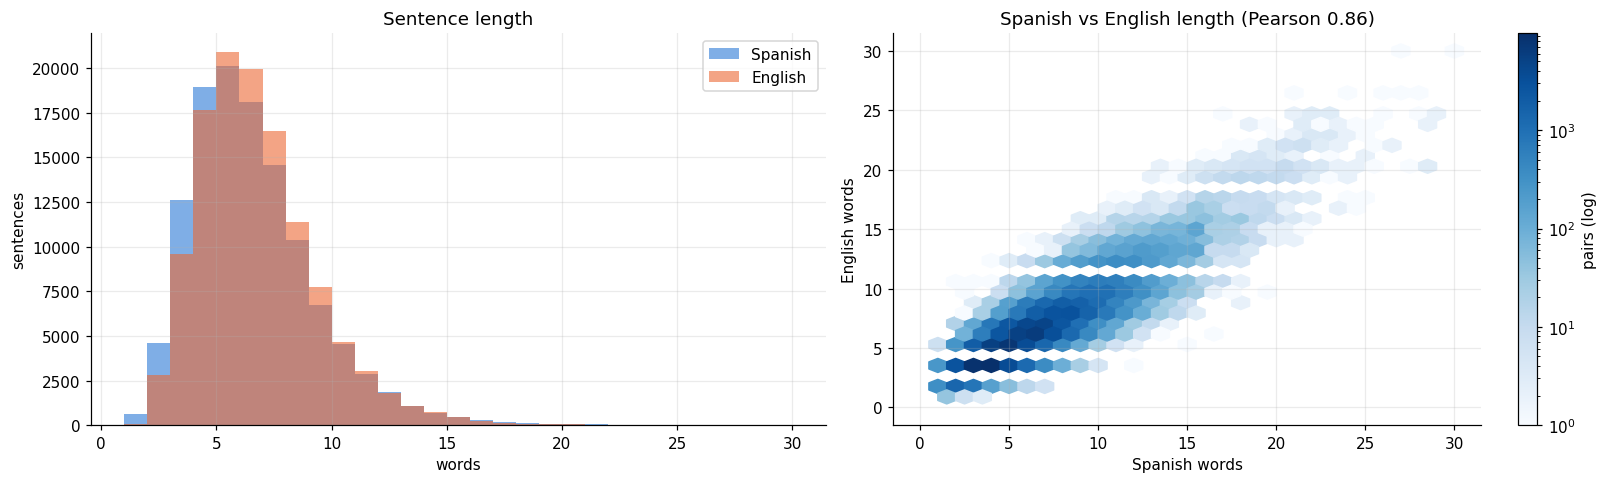

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

bins = np.arange(1, 31)
axes[0].hist(words["es"], bins=bins, alpha=0.6, color=PALETTE[0], label="Spanish")
axes[0].hist(words["en"], bins=bins, alpha=0.6, color=PALETTE[1], label="English")
axes[0].set(title="Sentence length", xlabel="words", ylabel="sentences")
axes[0].legend()

hb = axes[1].hexbin(words["es"], words["en"], gridsize=30, extent=(0, 30, 0, 30), mincnt=1, bins="log", cmap="Blues")
axes[1].set(title=f"Spanish vs English length (Pearson {words['es'].corr(words['en']):.2f})", xlabel="Spanish words", ylabel="English words")
fig.colorbar(hb, ax=axes[1], label="pairs (log)")

fig.tight_layout()
plt.show()

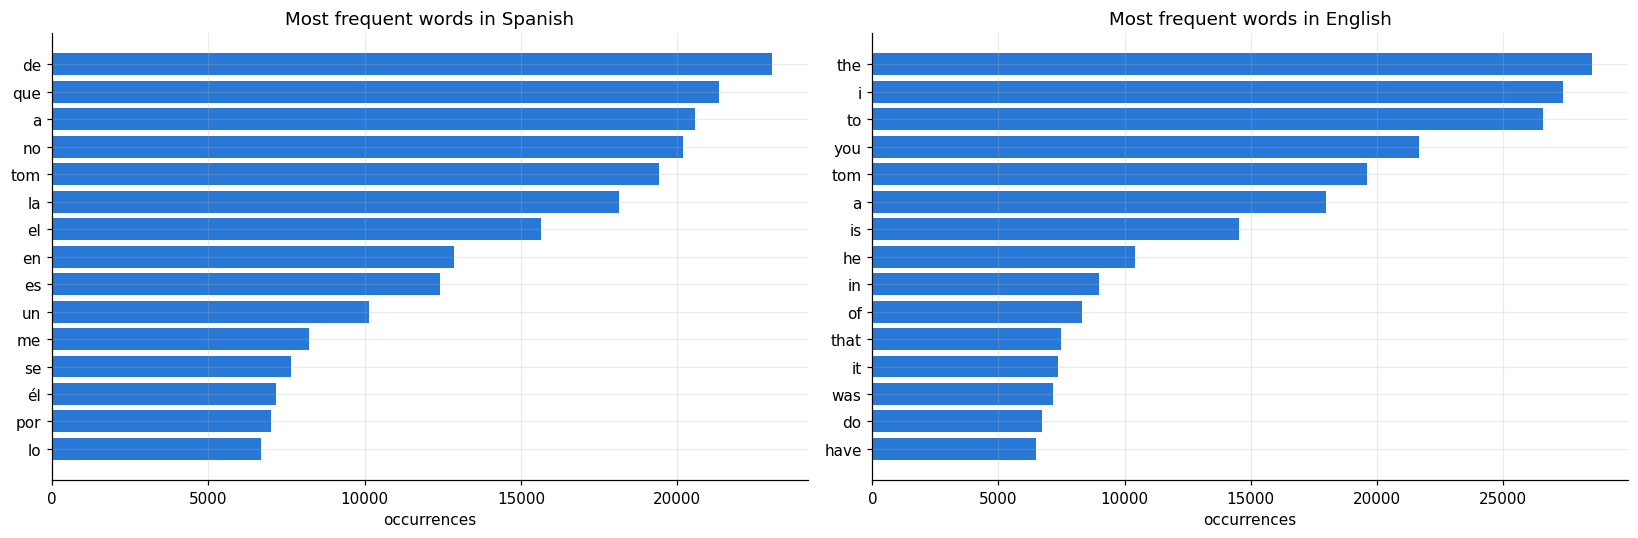

English sentences mentioning Tom: 17.1%


In [6]:
def top_words(series, n=15):
    return series.str.lower().str.findall(r"[a-záéíóúüñ']+").explode().value_counts().head(n)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, lang, title in zip(axes, ["es", "en"], ["Spanish", "English"]):
    top = top_words(raw[lang])
    ax.barh(top.index, top.values, color=PALETTE[0])
    ax.set(title=f"Most frequent words in {title}", xlabel="occurrences")
fig.tight_layout()
plt.show()

tom_share = raw["en"].str.contains(r"\bTom\b").mean()
print(f"English sentences mentioning Tom: {tom_share:.1%}")

### 2.2 OPUS-100 en-es

OPUS-100 has 1,000,000 training pairs and 2,000 validation and test pairs. It mixes movie subtitles, UN and EU documents, drug leaflets and software manuals. A sample review shows problems that must be cleaned first: misaligned pairs (*"Good night, ma'am."* → *"Esta tarde, hubo conciertos..."*), untranslated names, URLs, codes, software markup (`& kchart;`) and song lyrics marked with ♪ or #.

In [7]:
opus = load_dataset("Helsinki-NLP/opus-100", "en-es")
opus_raw = {
    split: opus[split].flatten().to_pandas().rename(columns={"translation.en": "en", "translation.es": "es"})[["en", "es"]]
    for split in ("train", "validation", "test")
}
print(pd.Series({split: len(frame) for split, frame in opus_raw.items()}, name="pairs").to_string())
opus_raw["train"].sample(10, random_state=SEED)

README.md:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

en-es/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237kB            

en-es/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 99.6MB            

en-es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1000000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

train         1000000
validation       2000
test             2000


,en,es
229916,Cell members come together and soak in the presence of God under the guidance of anointed worshi...,Y aquí es donde la adoración en el grupo más grande puede ser una experiencia transformadora don...
443987,One-day tour. We will start at Chequereq going towards Maras. Visit to the Moray archaeological ...,"Tour de un día, el cual iniciamos en Chequereq con dirección a Maras."
276251,She must have been dragged out from under the table.,Debe haber sido sacada a rastras de debajo de la mesa.
183701,What'll you do there?,¿Qué van a hacer allí?
749614,Is a metaphor.,Es una metáfora.
987038,So he lied.,Así que mintió.
265626,"In paragraph 4, the General Assembly calls on both sides to start the comprehensive and immediat...","En el párrafo 4, la Asamblea General exhorta a las dos partes a que comiencen a poner en práctic..."
771759,"It Weighs 50,000 KG and ranges over 8,000 meters",Su peso es de 50.000 kg y los rangos de más de 8.000 metros
571963,- Maybe even probation.,- Puede que en condicional.
881642,Dad and I love each other as always.,Papá y yo nos queremos lo mismo que siempre.


**Coherence filters** (applied in this order; each pair is dropped by the first one it fails):
1. **empty**: one side is empty after removing the leading dialogue dash (`- Hola.` → `Hola.`).
2. **untranslated**: Spanish and English are identical (names, numbers, codes).
3. **url or markup**: links or entities like `& kchart;`.
4. **song lyrics**: lines with ♪, ¶ or #.
5. **few letters**: fewer than half of the non-space characters are letters.
6. **too long**: more than 40 words on either side.
7. **inconsistent length**: the Spanish/English character ratio falls outside [0.5, 2.0]. The range comes from spa-eng, where 98% of the pairs are between 0.62 and 1.66.
8. **wrong language**: the Spanish side has more typical English words than Spanish ones, or vice versa.

Duplicated pairs are removed at the end.

In [8]:
class OpusCleaner:
    letters = r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]"
    markup = r"https?://|www\.|&\s*\w+;"
    es_words = {"el", "la", "los", "las", "que", "de", "del", "y", "en", "una", "por", "para", "con", "es", "se"}
    en_words = {"the", "and", "you", "is", "are", "this", "that", "with", "what", "of", "to", "it"}

    def __init__(self, min_ratio=0.5, max_ratio=2.0, max_words=40, min_letter_share=0.5):
        self.min_ratio = min_ratio
        self.max_ratio = max_ratio
        self.max_words = max_words
        self.min_letter_share = min_letter_share

    @staticmethod
    def normalize(series):
        return series.str.replace(r"^\s*-\s*", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

    def letter_share(self, series):
        return series.str.count(self.letters) / series.str.count(r"\S").clip(lower=1)

    @staticmethod
    def count_words(series, vocabulary):
        return series.str.findall(r"[a-záéíóúüñ']+").map(lambda words: sum(w in vocabulary for w in words))

    def audit(self, frame):
        es, en = self.normalize(frame["es"]), self.normalize(frame["en"])
        es_lower, en_lower = es.str.lower(), en.str.lower()
        ratio = es.str.len() / en.str.len().clip(lower=1)
        checks = {
            "empty": (es == "") | (en == ""),
            "untranslated": es_lower == en_lower,
            "url or markup": es.str.contains(self.markup) | en.str.contains(self.markup),
            "song lyrics": es.str.contains("[♪¶#]") | en.str.contains("[♪¶#]"),
            "few letters": (self.letter_share(es) < self.min_letter_share) | (self.letter_share(en) < self.min_letter_share),
            "too long": (es.str.split().str.len() > self.max_words) | (en.str.split().str.len() > self.max_words),
            "inconsistent length": ~ratio.between(self.min_ratio, self.max_ratio),
            "wrong language": (self.count_words(es_lower, self.en_words) > self.count_words(es_lower, self.es_words))
                              | (self.count_words(en_lower, self.es_words) > self.count_words(en_lower, self.en_words)),
        }
        reason = pd.Series(np.nan, index=frame.index, dtype=object)
        for name, mask in reversed(list(checks.items())):
            reason[mask] = name
        return pd.DataFrame({"es": es, "en": en, "reason": reason})

    def clean(self, frame):
        audited = self.audit(frame)
        valid = audited[audited["reason"].isna()]
        clean = valid[["es", "en"]].drop_duplicates().reset_index(drop=True)
        summary = audited["reason"].value_counts()
        summary["duplicate"] = len(valid) - len(clean)
        summary["kept"] = len(clean)
        return clean, audited, summary


cleaner = OpusCleaner()
opus_clean, opus_audit, opus_summary = {}, {}, {}
for split, frame in opus_raw.items():
    opus_clean[split], opus_audit[split], opus_summary[split] = cleaner.clean(frame)

summary = pd.DataFrame(opus_summary).fillna(0).astype(int)
summary["% train"] = (100 * summary["train"] / len(opus_raw["train"])).round(2)
summary

,train,validation,test,% train
reason,,,,
duplicate,70018,2,1,7.00
empty,28,0,0,0.00
few letters,8124,10,13,0.81
inconsistent length,34268,58,70,3.43
kept,811655,1758,1745,81.17
song lyrics,3900,7,7,0.39
too long,47918,124,137,4.79
untranslated,20289,30,22,2.03
url or markup,1862,8,3,0.19


In [9]:
discarded = opus_audit["train"].dropna(subset=["reason"])
discarded.sample(frac=1, random_state=SEED).groupby("reason").head(3).sort_values("reason")[["reason", "es", "en"]]

,reason,es,en
332436,empty,,Might as well.
683092,empty,,
226360,empty,¡Adelante!,
120060,few letters,"Y entonces, de vez en cuando...",_
565199,few letters,...entonces a las 7:30.,"7:30, then."
492391,few letters,Me ha impresionado que la estabilidad de los precios esté muy presente en las mentes de todos lo...,.
126353,inconsistent length,No pares. - Chicos... chicos.,"Guys, guys."
26752,inconsistent length,"Christina, perdóname por haberte mentido todo este tiempo. No hay problema.",chri* sorry** that's okay.
730673,inconsistent length,No te preocupes.,"Ah, don't you worry about a thing."
523413,song lyrics,# en la cuna de los amorosos brazos del Señor # # detrás de la noche # # oye a los ángeles dormi...,♪ in the cradle of the Lord's loving arms ♪ ♪ behind the night ♪ ♪ hear the angels fall asleep s...


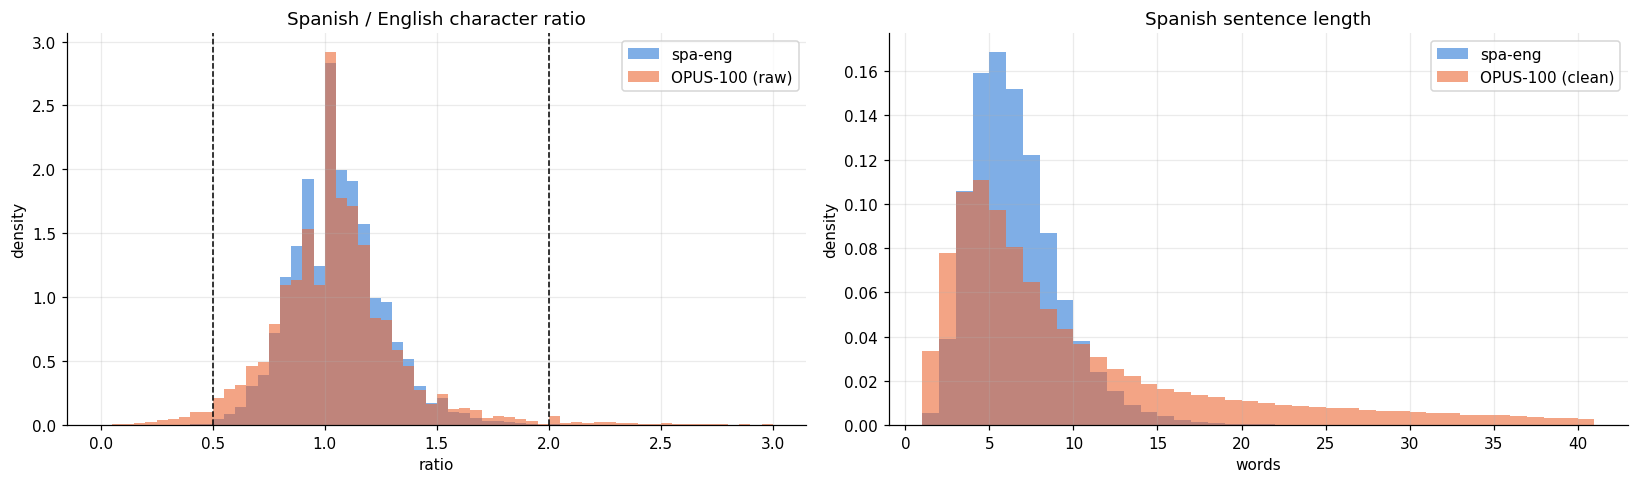

In [10]:
tatoeba_ratio = raw["es"].str.len() / raw["en"].str.len()
opus_ratio = opus_audit["train"]["es"].str.len() / opus_audit["train"]["en"].str.len().clip(lower=1)
opus_words = opus_clean["train"]["es"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.linspace(0, 3, 61)
axes[0].hist(tatoeba_ratio, bins=bins, density=True, alpha=0.6, color=PALETTE[0], label="spa-eng")
axes[0].hist(opus_ratio, bins=bins, density=True, alpha=0.6, color=PALETTE[1], label="OPUS-100 (raw)")
for bound in (cleaner.min_ratio, cleaner.max_ratio):
    axes[0].axvline(bound, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Spanish / English character ratio", xlabel="ratio", ylabel="density")
axes[0].legend()

bins = np.arange(1, 42)
axes[1].hist(words["es"], bins=bins, density=True, alpha=0.6, color=PALETTE[0], label="spa-eng")
axes[1].hist(opus_words, bins=bins, density=True, alpha=0.6, color=PALETTE[1], label="OPUS-100 (clean)")
axes[1].set(title="Spanish sentence length", xlabel="words", ylabel="density")
axes[1].legend()

fig.tight_layout()
plt.show()

In [11]:
opus_clean["train"].sample(15, random_state=SEED)

,es,en
10399,Te han oído...,You were heard.
207571,Voy a viajar.,I'm going to travel.
173399,Herr Zweig era un miembro prominente de Ia comunidad judaica.,Herr Zweig was a prominent member of the Jewish community.
719258,"No, me refiero a... ¿una botella de agua?","No, I meant... bottled water?"
752282,Trevor y Scott estuvieron en su granja y vieron las deplorables condiciones.,Trevor and Scott were both at his farm and said the conditions were deplorable.
578845,El hombre en sociedad debe tomar algunas decisiones acerca de los aciertos o equívocos de cierto...,INTERVIEWER 3: Yet man in society must make some decisions about the rights and wrongs of certai...
350606,"Ahora que no hay bebé, el divorcio será más sencillo.","Now that there's no baby, it'll make the divorce a lot simpler."
794911,"Te extrañé, Eun Young.","I missed you, Eun Young."
770442,"Costa Rica adoptó, a través de la Ley Nº 5980, la Convención para la Protección del Patrimonio M...","By Law No. 980, Costa Rica adopted the Convention Concerning the Protection of the World Cultura..."
787860,"Nuestro carro era marrón, este carro es marrón.","Our buggy was tan, this buggy is tan."


### 2.3 Final mix

The full spa-eng corpus is combined with **400,000 pairs** of clean OPUS-100 for training. Validation and test join the matching spa-eng split with the official (also cleaned) OPUS-100 validation and test sets. Finally, duplicated pairs and any Spanish sentence that appears in validation or test are removed from train.

## 3. Tokenizer and dataset

In [12]:
def split_by_source(frame, val_frac, test_frac, seed):
    sources = frame["es"].drop_duplicates().sample(frac=1, random_state=seed).to_numpy()
    n_val, n_test = int(len(sources) * val_frac), int(len(sources) * test_frac)
    groups = {"test": sources[:n_test], "val": sources[n_test:n_test + n_val], "train": sources[n_test + n_val:]}
    return {name: frame[frame["es"].isin(set(group))].reset_index(drop=True) for name, group in groups.items()}

OPUS_TRAIN_PAIRS = 400_000

tatoeba = split_by_source(raw, val_frac=0.05, test_frac=0.05, seed=SEED)
opus_parts = {
    "train": opus_clean["train"].sample(min(OPUS_TRAIN_PAIRS, len(opus_clean["train"])), random_state=SEED),
    "val": opus_clean["validation"],
    "test": opus_clean["test"],
}
splits = {
    name: pd.concat([tatoeba[name].assign(source="spa-eng"), opus_parts[name].assign(source="opus")], ignore_index=True)
    for name in ("train", "val", "test")
}
held_out = set(splits["val"]["es"]) | set(splits["test"]["es"])
splits["train"] = splits["train"][~splits["train"]["es"].isin(held_out)].drop_duplicates(["es", "en"]).reset_index(drop=True)

pd.DataFrame({name: frame["source"].value_counts() for name, frame in splits.items()}).T.assign(total=lambda d: d.sum(axis=1))

source,opus,spa-eng,total
train,397544,107062,504606
val,1758,5926,7684
test,1745,5930,7675


The tokenizer is a **byte-level BPE** (the same kind GPT-2 uses), trained from scratch on the training sentences in both languages, so the vocabulary fits the Spanish and English of this mix. OPUS makes the vocabulary much more varied, so 16,000 tokens are used. Four special tokens are added: `<pad>`, `<es>`, `<en>` and `<eos>`.

In [13]:
class BilingualTokenizer:
    specials = ["<pad>", "<es>", "<en>", "<eos>"]

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.pad_id, self.es_id, self.en_id, self.eos_id = (tokenizer.token_to_id(t) for t in self.specials)

    @classmethod
    def train(cls, texts, vocab_size):
        tokenizer = Tokenizer(models.BPE())
        tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tokenizer.decoder = decoders.ByteLevel()
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=cls.specials, show_progress=False,
                                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
        tokenizer.train_from_iterator(texts, trainer)
        return cls(tokenizer)

    @property
    def vocab_size(self):
        return self.tokenizer.get_vocab_size()

    def encode(self, texts):
        return [e.ids for e in self.tokenizer.encode_batch(list(texts))]

    def decode(self, ids):
        return self.tokenizer.decode(ids)

    def pieces(self, ids):
        return [self.tokenizer.decode([i], skip_special_tokens=False) for i in ids]

    def prompt(self, source_ids):
        return [self.es_id, *source_ids, self.en_id]


tokenizer = BilingualTokenizer.train(pd.concat([splits["train"]["es"], splits["train"]["en"]]), vocab_size=16000)
tokenizer.tokenizer.save(str(WORK_DIR / "tokenizer.json"))
print("vocabulary:", tokenizer.vocab_size)

for sentence in ["¿Dónde está la estación de tren?", "Where is the train station?"]:
    print(" | ".join(tokenizer.pieces(tokenizer.encode([sentence])[0])))

vocabulary: 16000
¿ | Dónde |  está |  la |  estación |  de |  tren | ?
Where |  is |  the |  train |  station | ?


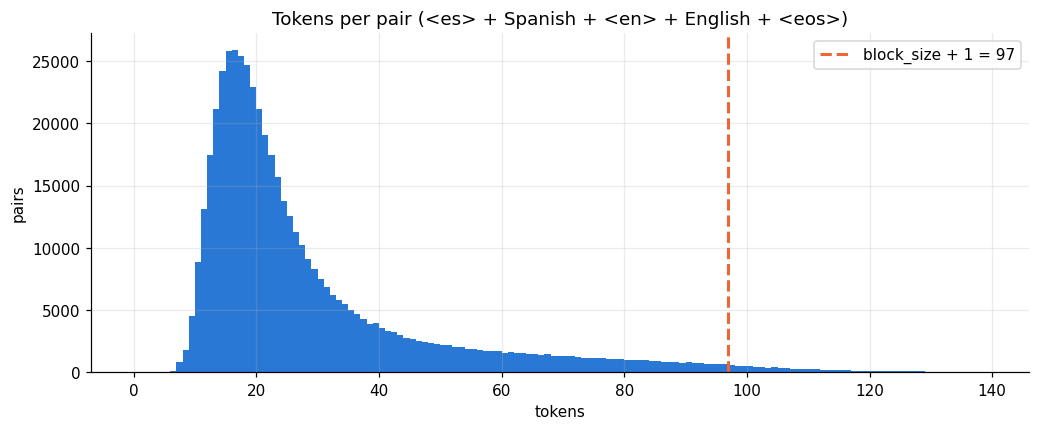

train: 98.50% of the pairs kept | opus 98.10% | spa-eng 100.00%
val  : 99.32% of the pairs kept | opus 97.10% | spa-eng 99.98%
test : 99.57% of the pairs kept | opus 98.11% | spa-eng 100.00%


In [14]:
BLOCK_SIZE = 96

pair_tokens = {
    name: np.array([len(s) + len(t) + 3 for s, t in zip(tokenizer.encode(frame["es"]), tokenizer.encode(frame["en"]))])
    for name, frame in splits.items()
}

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(pair_tokens["train"], bins=np.arange(0, 140), color=PALETTE[0])
ax.axvline(BLOCK_SIZE + 1, color=PALETTE[1], linestyle="--", label=f"block_size + 1 = {BLOCK_SIZE + 1}")
ax.set(title="Tokens per pair (<es> + Spanish + <en> + English + <eos>)", xlabel="tokens", ylabel="pairs")
ax.legend()
plt.show()

for name in splits:
    keep = pair_tokens[name] <= BLOCK_SIZE + 1
    by_source = splits[name].assign(keep=keep).groupby("source")["keep"].mean()
    print(f"{name:5s}: {keep.mean():.2%} of the pairs kept | " + " | ".join(f"{k} {v:.2%}" for k, v in by_source.items()))
    splits[name] = splits[name][keep].reset_index(drop=True)

Each pair becomes `x` (input) and `y` (target shifted by one position). The positions of the Spanish prompt are set to `-1` in `y`, so the loss is computed **only on the English translation and `<eos>`**.

**Length-bucketed batches.** With random batches, every batch is padded to its longest sentence, and since the mix contains very short and very long sentences, a large share of each batch is padding that the GPU processes for nothing. `LengthBucketSampler` shuffles the data, cuts it into large buckets (100 batches each), sorts each bucket by length, builds the batches and then shuffles the batch order. Every epoch still sees the data in a different random order, but each batch holds sentences of similar length.

In [15]:
class TranslationDataset(Dataset):
    def __init__(self, frame, tokenizer):
        self.tokenizer = tokenizer
        self.sources = tokenizer.encode(frame["es"])
        self.targets = tokenizer.encode(frame["en"])
        self.lengths = np.array([len(s) + len(t) + 2 for s, t in zip(self.sources, self.targets)])

    def __len__(self):
        return len(self.sources)

    def __getitem__(self, i):
        prompt = self.tokenizer.prompt(self.sources[i])
        sequence = torch.tensor(prompt + self.targets[i] + [self.tokenizer.eos_id])
        x, y = sequence[:-1], sequence[1:].clone()
        y[:len(prompt) - 1] = -1
        return x, y

    def collate(self, batch):
        xs, ys = zip(*batch)
        x = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=self.tokenizer.pad_id)
        y = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=-1)
        return x, y

class LengthBucketSampler(Sampler):
    def __init__(self, lengths, batch_size, shuffle, bucket_batches=100, seed=SEED):
        self.lengths = lengths
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.bucket_size = batch_size * bucket_batches
        self.seed = seed
        self.epoch = 0

    def batches(self):
        if not self.shuffle:
            order = np.argsort(self.lengths, kind="stable")
            return [order[i:i + self.batch_size] for i in range(0, len(order), self.batch_size)]
        rng = np.random.default_rng(self.seed + self.epoch)
        order = rng.permutation(len(self.lengths))
        batches = []
        for start in range(0, len(order), self.bucket_size):
            bucket = order[start:start + self.bucket_size]
            bucket = bucket[np.argsort(self.lengths[bucket], kind="stable")]
            batches += [bucket[i:i + self.batch_size] for i in range(0, len(bucket) - self.batch_size + 1, self.batch_size)]
        rng.shuffle(batches)
        return batches

    def __iter__(self):
        batches = self.batches()
        self.epoch += 1
        return iter([batch.tolist() for batch in batches])

    def __len__(self):
        return len(self.batches())

datasets = {name: TranslationDataset(frame, tokenizer) for name, frame in splits.items()}

x, y = datasets["train"][0]
print("x:", " | ".join(tokenizer.pieces(x.tolist())))
print("y:", " | ".join("·" if t == -1 else tokenizer.pieces([t])[0] for t in y.tolist()))

x: <es> | Ve | . | <en> | Go | .
y: · | · | · | Go | . | <eos>


In [16]:
lengths = datasets["train"].lengths
rng = np.random.default_rng(SEED)
random_batches = np.array_split(rng.permutation(len(lengths)), len(lengths) // 256)
bucketed_batches = LengthBucketSampler(lengths, 256, shuffle=True).batches()

def padding_stats(batches):
    processed = sum(len(b) * lengths[b].max() for b in batches)
    real = sum(lengths[b].sum() for b in batches)
    return {"tokens processed (M)": processed / 1e6, "padding share": 1 - real / processed}

pd.DataFrame({"random batches": padding_stats(random_batches), "bucketed batches": padding_stats(bucketed_batches)}).round(3)

,random batches,bucketed batches
tokens processed (M),46.441,13.403
padding share,0.716,0.017


## 4. Model

minGPT architecture: token and position embeddings, `LayerNorm → causal attention → LayerNorm → MLP` blocks with residual connections, and a final `lm_head`. Attention uses `scaled_dot_product_attention` for speed, and minGPT's explicit version only when the attention maps are stored for plotting.

In [17]:
@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int
    n_layer: int = 6
    n_head: int = 8
    n_embd: int = 512
    dropout: float = 0.1
    label_smoothing: float = 0.1

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head = config.n_head
        self.store_attention = False
        self.attention = None

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        if self.store_attention:
            att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
            att = att.masked_fill(~torch.ones(T, T, dtype=torch.bool, device=x.device).tril(), float("-inf")).softmax(dim=-1)
            self.attention = att.detach()
            y = self.attn_dropout(att) @ v
        else:
            y = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.c_proj(y))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = nn.Sequential(
            nn.Linear(config.n_embd, 4 * config.n_embd),
            nn.GELU(approximate="tanh"),
            nn.Linear(4 * config.n_embd, config.n_embd),
            nn.Dropout(config.dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        return x + self.mlp(self.ln_2(x))

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.apply(self._init_weights)
        self.lm_head.weight = self.transformer.wte.weight
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight") or name.endswith("mlp.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer))

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def forward(self, idx, targets=None):
        pos = torch.arange(idx.size(1), device=idx.device)
        x = self.transformer.drop(self.transformer.wte(idx) + self.transformer.wpe(pos))
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        if targets is None:
            return self.lm_head(x[:, [-1], :])
        logits = self.lm_head(x)
        smoothing = self.config.label_smoothing if self.training else 0.0
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1, label_smoothing=smoothing)
        return loss.unsqueeze(0)

    def configure_optimizers(self, config):
        decay = [p for n, p in self.named_parameters() if p.dim() >= 2 and "wte" not in n and "wpe" not in n]
        no_decay = [p for n, p in self.named_parameters() if p.dim() < 2 or "wte" in n or "wpe" in n]
        groups = [{"params": decay, "weight_decay": config.weight_decay}, {"params": no_decay, "weight_decay": 0.0}]
        return torch.optim.AdamW(groups, lr=config.learning_rate, betas=config.betas)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, eos_id):
        finished = torch.zeros(idx.size(0), dtype=torch.bool, device=idx.device)
        for _ in range(max_new_tokens):
            logits = self(idx[:, -self.config.block_size:])
            next_id = logits[:, -1, :].argmax(dim=-1, keepdim=True)
            next_id = next_id.masked_fill(finished[:, None], eos_id)
            finished |= next_id.squeeze(1) == eos_id
            idx = torch.cat((idx, next_id), dim=1)
            if finished.all():
                break
        return idx

    def parameter_table(self):
        rows = []
        for name, p in self.named_parameters():
            parts = name.split(".")
            if parts[1] != "h":
                layer, group = parts[1], {"wte": "token_embedding + lm_head", "wpe": "position_embedding", "ln_f": "layernorm"}[parts[1]]
            else:
                layer, group = f"block_{parts[2]}", {"attn": "attention", "mlp": "mlp"}.get(parts[3], "layernorm")
            rows.append(dict(name=name, layer=layer, group=group, shape=tuple(p.shape), params=p.numel()))
        return pd.DataFrame(rows)

In [18]:
model_config = GPTConfig(vocab_size=tokenizer.vocab_size, block_size=BLOCK_SIZE)
model = GPT(model_config)
print(model)
pd.Series(asdict(model_config), name="value", dtype=object).to_frame()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(16000, 512)
    (wpe): Embedding(96, 512)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-5): 6 x Block(
        (ln_1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=512, out_features=1536, bias=True)
          (c_proj): Linear(in_features=512, out_features=512, bias=True)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (mlp): Sequential(
          (0): Linear(in_features=512, out_features=2048, bias=True)
          (1): GELU(approximate='tanh')
          (2): Linear(in_features=2048, out_features=512, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_fe

,value
vocab_size,16000
block_size,96
n_layer,6
n_head,8
n_embd,512
dropout,0.1
label_smoothing,0.1


Total parameters:              27.16M (lm_head shares weights with the token embedding)
Target tokens in train:        6.55M
Target tokens per parameter:   0.24


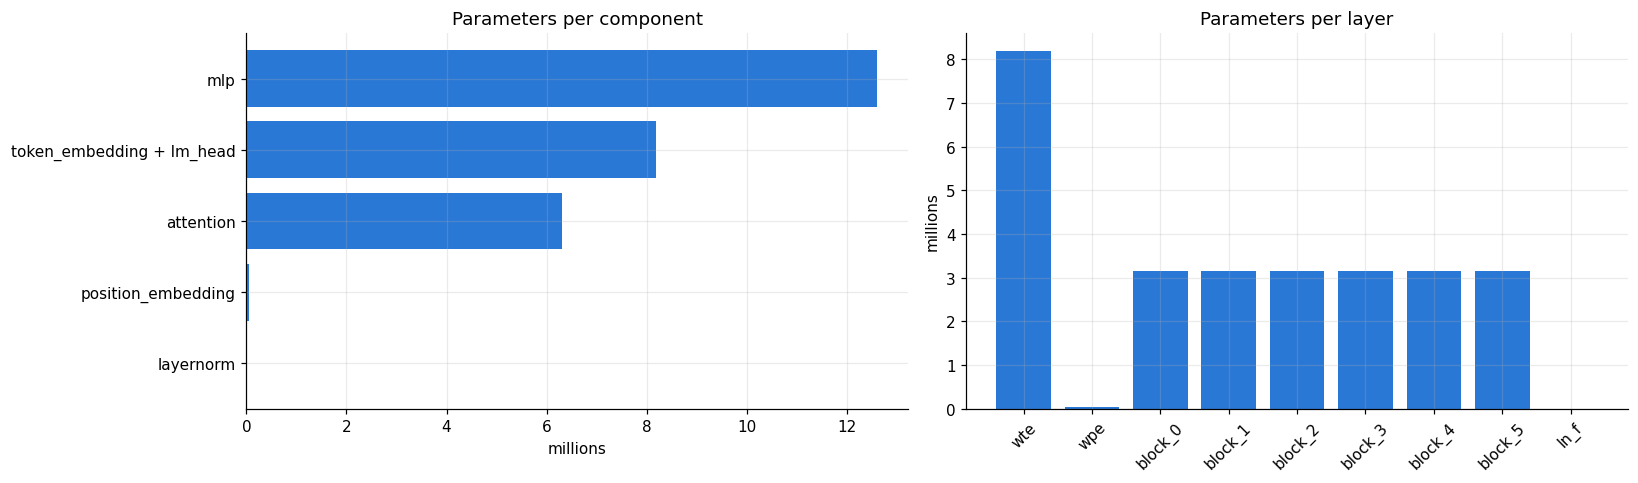

,parameters,%
group,,
mlp,12598272,46.39
token_embedding + lm_head,8192000,30.17
attention,6303744,23.21
position_embedding,49152,0.18
layernorm,13312,0.05


In [19]:
params = model.parameter_table()
n_params = params["params"].sum()
train_targets = sum(len(t) + 1 for t in datasets["train"].targets)

print(f"Total parameters:              {n_params / 1e6:.2f}M (lm_head shares weights with the token embedding)")
print(f"Target tokens in train:        {train_targets / 1e6:.2f}M")
print(f"Target tokens per parameter:   {train_targets / n_params:.2f}")

by_group = params.groupby("group")["params"].sum().sort_values()
by_layer = params.groupby("layer", sort=False)["params"].sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].barh(by_group.index, by_group.values / 1e6, color=PALETTE[0])
axes[0].set(title="Parameters per component", xlabel="millions")
axes[1].bar(by_layer.index, by_layer.values / 1e6, color=PALETTE[0])
axes[1].set(title="Parameters per layer", ylabel="millions")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

by_group.to_frame("parameters").assign(**{"%": lambda d: (100 * d["parameters"] / n_params).round(2)})[::-1]

## 5. Trainer

In [20]:
@dataclass
class TrainConfig:
    batch_size: int = 256
    learning_rate: float = 6e-4
    min_lr_ratio: float = 0.1
    warmup_steps: int = 300
    max_epochs: int = 20
    weight_decay: float = 0.1
    betas: tuple = (0.9, 0.95)
    grad_norm_clip: float = 1.0
    patience: int = 3
    log_interval: int = 20

class Trainer:
    def __init__(self, model, config, train_ds, val_ds, n_gpus):
        self.model = model.to(DEVICE)
        self.net = nn.DataParallel(model) if n_gpus > 1 else model
        self.config = config
        self.optimizer = model.configure_optimizers(config)
        self.use_amp = DEVICE.type == "cuda"
        self.scaler = torch.amp.GradScaler("cuda", enabled=self.use_amp)
        self.train_loader = DataLoader(train_ds, batch_sampler=LengthBucketSampler(train_ds.lengths, config.batch_size, shuffle=True),
                                       collate_fn=train_ds.collate, num_workers=2, pin_memory=self.use_amp, persistent_workers=True)
        self.val_loader = DataLoader(val_ds, batch_sampler=LengthBucketSampler(val_ds.lengths, config.batch_size, shuffle=False),
                                     collate_fn=val_ds.collate, num_workers=2, pin_memory=self.use_amp)
        self.total_steps = len(self.train_loader) * config.max_epochs
        self.step = 0
        self.history = {"steps": [], "epochs": []}

    def lr_at(self, step):
        c = self.config
        if step < c.warmup_steps:
            return c.learning_rate * (step + 1) / c.warmup_steps
        progress = min(1.0, (step - c.warmup_steps) / (self.total_steps - c.warmup_steps))
        return c.learning_rate * (c.min_lr_ratio + (1 - c.min_lr_ratio) * 0.5 * (1 + math.cos(math.pi * progress)))

    def train_step(self, x, y):
        lr = self.lr_at(self.step)
        for group in self.optimizer.param_groups:
            group["lr"] = lr
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=self.use_amp):
            loss = self.net(x, y).mean()
        self.optimizer.zero_grad(set_to_none=True)
        self.scaler.scale(loss).backward()
        self.scaler.unscale_(self.optimizer)
        grad_norm = nn.utils.clip_grad_norm_(self.model.parameters(), self.config.grad_norm_clip)
        self.scaler.step(self.optimizer)
        self.scaler.update()
        self.step += 1
        return loss.detach(), grad_norm.detach(), lr

    @torch.no_grad()
    def evaluate(self):
        self.net.eval()
        total, count = 0.0, 0
        for x, y in self.val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=self.use_amp):
                loss = self.net(x, y).mean()
            n = int((y != -1).sum())
            total, count = total + loss.item() * n, count + n
        self.net.train()
        return total / count

    def benchmark(self, steps, warmup=10):
        self.net.train()
        batches = iter(self.train_loader)
        tokens = 0
        for i in range(warmup + steps):
            if i == warmup:
                torch.cuda.synchronize()
                start, tokens = time.time(), 0
            x, y = next(batches)
            self.train_step(x, y)
            tokens += x.numel()
        torch.cuda.synchronize()
        return tokens / (time.time() - start)

    def fit(self, on_epoch_end=None):
        best_loss, best_state, bad_epochs = float("inf"), None, 0
        for epoch in range(1, self.config.max_epochs + 1):
            self.net.train()
            start = time.time()
            epoch_loss = torch.zeros((), device=DEVICE)
            for i, (x, y) in enumerate(self.train_loader, start=1):
                loss, grad_norm, lr = self.train_step(x, y)
                epoch_loss += loss
                if self.step % self.config.log_interval == 0:
                    self.history["steps"].append(dict(step=self.step, loss=loss.item(), grad_norm=grad_norm.item(), lr=lr))
            record = dict(epoch=epoch, step=self.step, train_loss=(epoch_loss / i).item(), val_loss=self.evaluate(),
                          time_sec=time.time() - start)
            record.update(on_epoch_end(self) if on_epoch_end else {})
            improved = record["val_loss"] < best_loss
            if improved:
                best_loss, bad_epochs = record["val_loss"], 0
                best_state = copy.deepcopy(self.model.state_dict())
                torch.save(best_state, WORK_DIR / "best_model.pt")
            else:
                bad_epochs += 1
            self.history["epochs"].append(record)
            extra = " | ".join(f"{k} {v:.2f}" for k, v in record.items() if k not in ("epoch", "step", "train_loss", "val_loss", "time_sec"))
            print(f"epoch {epoch:2d} | train {record['train_loss']:.4f} | val {record['val_loss']:.4f} | {extra} | "
                  f"{record['time_sec']:.0f}s{' | best' if improved else ''}")
            if bad_epochs >= self.config.patience:
                print(f"early stopping: {self.config.patience} epochs without improving the validation loss")
                break
        self.model.load_state_dict(best_state)
        return self.history


train_config = TrainConfig()
pd.Series(asdict(train_config), name="value", dtype=object).to_frame()

,value
batch_size,256
learning_rate,0.0006
min_lr_ratio,0.1
warmup_steps,300
max_epochs,20
weight_decay,0.1
betas,"(0.9, 0.95)"
grad_norm_clip,1.0
patience,3
log_interval,20


## 7. Training

In [21]:
class Translator:
    def __init__(self, model, tokenizer, batch_size=512):
        self.model = model
        self.tokenizer = tokenizer
        self.batch_size = batch_size

    @torch.no_grad()
    def translate(self, sentences, max_new_tokens=BLOCK_SIZE):
        self.model.eval()
        prompts = [self.tokenizer.prompt(ids) for ids in self.tokenizer.encode(sentences)]
        outputs = [None] * len(prompts)
        by_length = pd.Series(range(len(prompts))).groupby([len(p) for p in prompts])
        for length, rows in by_length:
            rows = rows.tolist()
            for start in range(0, len(rows), self.batch_size):
                chunk = rows[start:start + self.batch_size]
                idx = torch.tensor([prompts[i] for i in chunk], device=DEVICE)
                with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                    generated = self.model.generate(idx, max_new_tokens, self.tokenizer.eos_id)[:, length:].tolist()
                for i, ids in zip(chunk, generated):
                    outputs[i] = self.tokenizer.decode(ids[:ids.index(self.tokenizer.eos_id)] if self.tokenizer.eos_id in ids else ids)
        return outputs

    def score(self, frame):
        predictions = self.translate(frame["es"])
        return {"bleu": sacrebleu.corpus_bleu(predictions, [frame["en"].tolist()]).score,
                "chrf": sacrebleu.corpus_chrf(predictions, [frame["en"].tolist()]).score}


val_sample = splits["val"].sample(1000, random_state=SEED)

In [24]:
torch.manual_seed(SEED)
model = GPT(model_config)
trainer = Trainer(model, train_config, datasets["train"], datasets["val"], N_GPUS)
translator = Translator(model, tokenizer)

start = time.time()
history = trainer.fit(on_epoch_end=lambda t: {"val_bleu": translator.score(val_sample)["bleu"]})
train_minutes = (time.time() - start) / 60
print(f"total time: {train_minutes:.1f} min")

epoch  1 | train 4.5842 | val 2.3199 | val_bleu 26.79 | 150s | best
epoch  2 | train 3.4753 | val 1.7806 | val_bleu 34.98 | 150s | best
epoch  3 | train 3.1456 | val 1.5729 | val_bleu 39.24 | 151s | best
epoch  4 | train 2.9841 | val 1.4780 | val_bleu 41.38 | 151s | best
epoch  5 | train 2.8820 | val 1.3971 | val_bleu 43.12 | 151s | best
epoch  6 | train 2.8022 | val 1.3386 | val_bleu 44.63 | 151s | best
epoch  7 | train 2.7389 | val 1.3190 | val_bleu 45.42 | 150s | best
epoch  8 | train 2.6814 | val 1.2818 | val_bleu 46.70 | 148s | best
epoch  9 | train 2.6288 | val 1.2532 | val_bleu 46.69 | 150s | best
epoch 10 | train 2.5787 | val 1.2284 | val_bleu 47.68 | 151s | best
epoch 11 | train 2.5317 | val 1.2021 | val_bleu 48.69 | 151s | best
epoch 12 | train 2.4839 | val 1.1885 | val_bleu 49.17 | 151s | best
epoch 13 | train 2.4371 | val 1.1820 | val_bleu 49.08 | 151s | best
epoch 14 | train 2.3935 | val 1.1693 | val_bleu 49.17 | 151s | best
epoch 15 | train 2.3519 | val 1.1605 | val_bleu 

## 8. Training metrics

In [25]:
steps = pd.DataFrame(history["steps"])
epochs = pd.DataFrame(history["epochs"]).assign(train_ppl=lambda d: np.exp(d["train_loss"]), val_ppl=lambda d: np.exp(d["val_loss"]))
epochs.round(4)

,epoch,step,train_loss,val_loss,time_sec,val_bleu,train_ppl,val_ppl
0,1,1941,4.5842,2.3199,149.7691,26.7915,97.9241,10.1744
1,2,3882,3.4753,1.7806,149.9359,34.9768,32.3078,5.9334
2,3,5823,3.1456,1.5729,151.3838,39.2412,23.2329,4.8204
3,4,7764,2.9841,1.4780,151.1536,41.3809,19.7682,4.3842
4,5,9705,2.8820,1.3971,151.3964,43.1206,17.8498,4.0436
5,6,11646,2.8022,1.3386,151.2145,44.6349,16.4807,3.8136
6,7,13587,2.7389,1.3190,150.0559,45.4225,15.4701,3.7397
7,8,15528,2.6814,1.2818,147.8349,46.7026,14.6056,3.6030
8,9,17469,2.6288,1.2532,149.6169,46.6860,13.8572,3.5014
9,10,19410,2.5787,1.2284,151.0355,47.6795,13.1803,3.4157


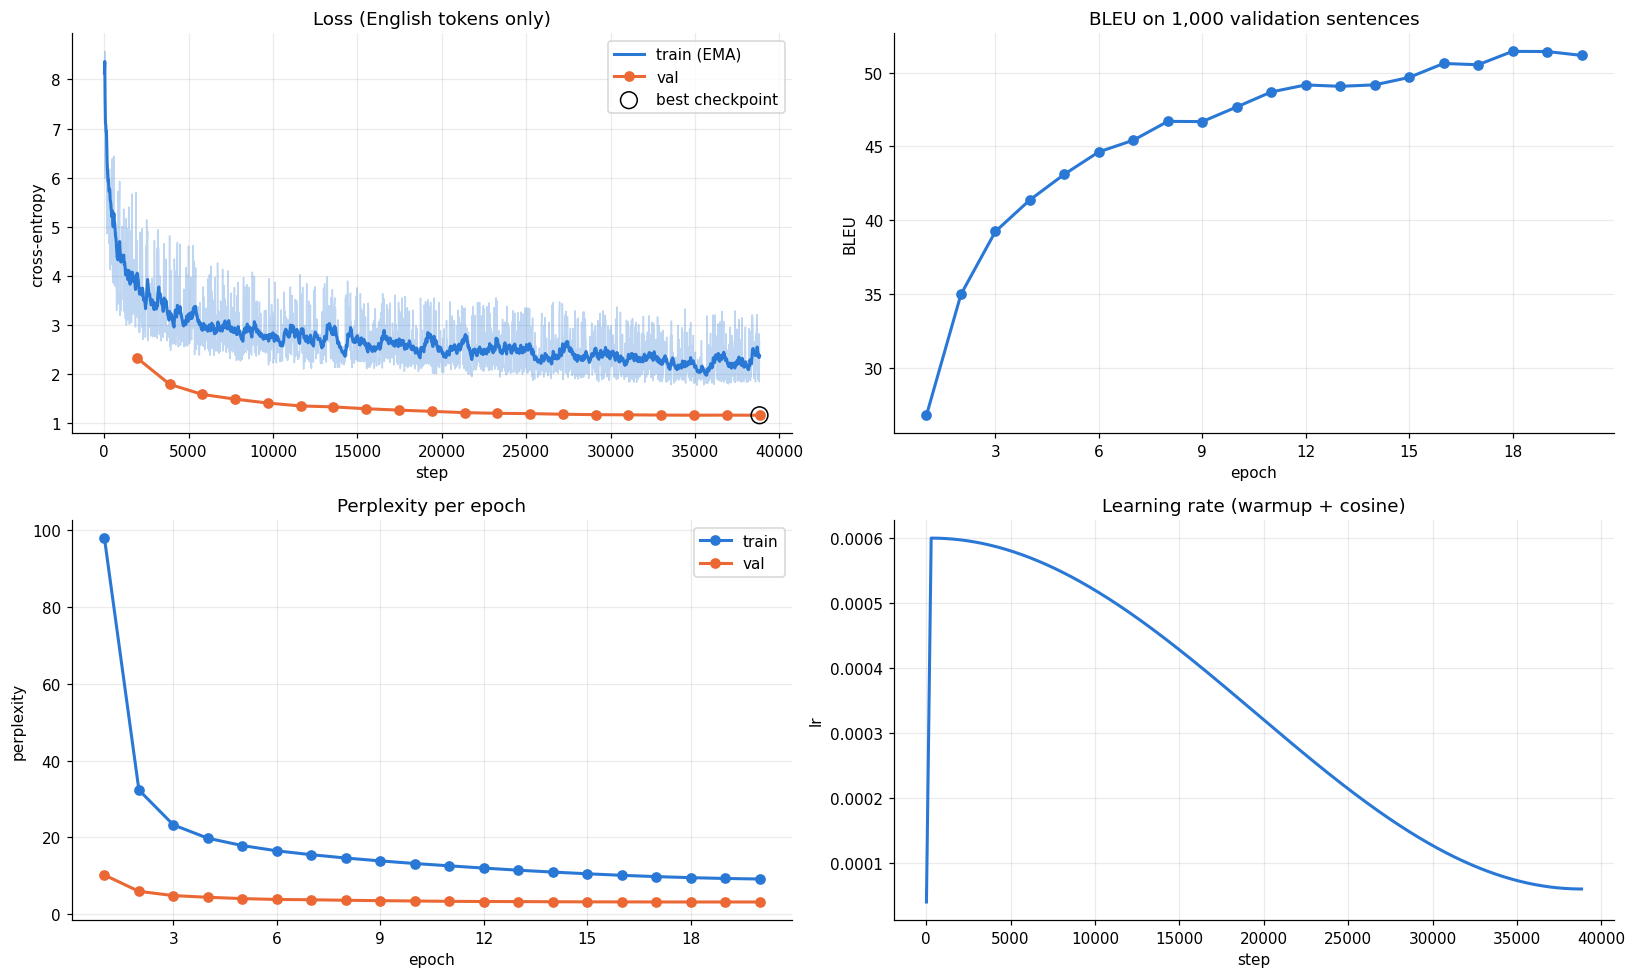

best epoch: 20 | val loss 1.1487 | val BLEU 51.17


In [26]:
best = epochs.loc[epochs["val_loss"].idxmin()]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

ax = axes[0, 0]
ax.plot(steps["step"], steps["loss"], color=PALETTE[0], alpha=0.3, linewidth=1)
ax.plot(steps["step"], steps["loss"].ewm(span=20).mean(), color=PALETTE[0], label="train (EMA)")
ax.plot(epochs["step"], epochs["val_loss"], color=PALETTE[1], marker="o", label="val")
ax.scatter([best["step"]], [best["val_loss"]], s=120, facecolors="none", edgecolors="black", zorder=3, label="best checkpoint")
ax.set(title="Loss (English tokens only)", xlabel="step", ylabel="cross-entropy")
ax.legend()

ax = axes[0, 1]
ax.plot(epochs["epoch"], epochs["val_bleu"], color=PALETTE[0], marker="o")
ax.set(title="BLEU on 1,000 validation sentences", xlabel="epoch", ylabel="BLEU")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax = axes[1, 0]
ax.plot(epochs["epoch"], epochs["train_ppl"], color=PALETTE[0], marker="o", label="train")
ax.plot(epochs["epoch"], epochs["val_ppl"], color=PALETTE[1], marker="o", label="val")
ax.set(title="Perplexity per epoch", xlabel="epoch", ylabel="perplexity")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()

ax = axes[1, 1]
ax.plot(steps["step"], steps["lr"], color=PALETTE[0])
ax.set(title="Learning rate (warmup + cosine)", xlabel="step", ylabel="lr")

fig.tight_layout()
plt.show()

print(f"best epoch: {int(best['epoch'])} | val loss {best['val_loss']:.4f} | val BLEU {best['val_bleu']:.2f}")

## 9. Testing

In [27]:
results = pd.DataFrame({name: translator.score(splits[name]) for name in ("val", "test")}).T
results.round(2)

,bleu,chrf
val,50.89,66.39
test,51.60,66.99


### 9.1 Test set examples

In [28]:
examples = splits["test"].sample(12, random_state=SEED).reset_index(drop=True)
examples["model"] = translator.translate(examples["es"])
examples.rename(columns={"es": "spanish", "en": "reference"})[["spanish", "reference", "model"]]

,spanish,reference,model
0,Él se agarró un resfriado cuando salió a la lluvia.,He caught a chill because he went out in the rain.,He caught a cold when it went out to the rain.
1,"Permiso, ¿puedo pasar?","Excuse me, could I get past?","Excuse me, may I come in?"
2,- Agitar .,Shake.,Arrival.
3,Este libro pertenece a Tom.,This book belongs to Tom.,This book belongs to Tom.
4,Libres...,Liberate...,Free.
5,Edición Jean Ravel,Editing Jean Ravel,Edition Jean Ravel
6,Fui criada por mi abuela.,I was brought up by my grandmother.,I was raised by my grandmother.
7,Estoy en paro.,I'm unemployed.,I'm in labor.
8,No me queda otra opción que desechar el caso sin cargos.,Then I have no choice but to dismiss this case without prejudice.,I have no choice but to discharge the case without charges.
9,María mintió acerca de su edad.,Mary lied about her age.,Mary lied about her age.


### 9.2 Quality by sentence length

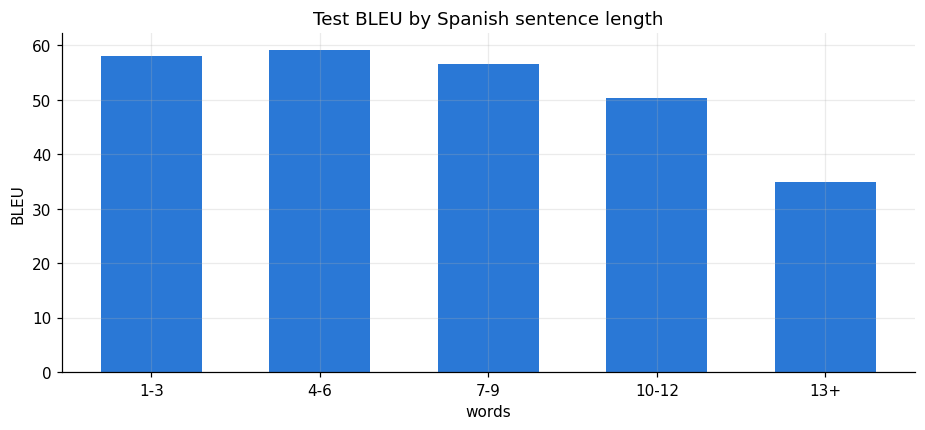

,sentences,bleu
bucket,,
1-3,1133.0,58.06
4-6,3421.0,59.23
7-9,1807.0,56.64
10-12,646.0,50.37
13+,635.0,34.97


In [29]:
test = splits["test"].assign(words=lambda d: d["es"].str.split().str.len())
test["model"] = translator.translate(test["es"])
test["bucket"] = pd.cut(test["words"], bins=[0, 3, 6, 9, 12, 100], labels=["1-3", "4-6", "7-9", "10-12", "13+"])

by_length = test.groupby("bucket", observed=True)[["model", "en"]].apply(
    lambda g: pd.Series({"sentences": len(g), "bleu": sacrebleu.corpus_bleu(g["model"].tolist(), [g["en"].tolist()]).score})
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_length.index.astype(str), by_length["bleu"], color=PALETTE[0], width=0.6)
ax.set(title="Test BLEU by Spanish sentence length", xlabel="words", ylabel="BLEU")
plt.show()
by_length.round(2)

### 9.3 Attention map

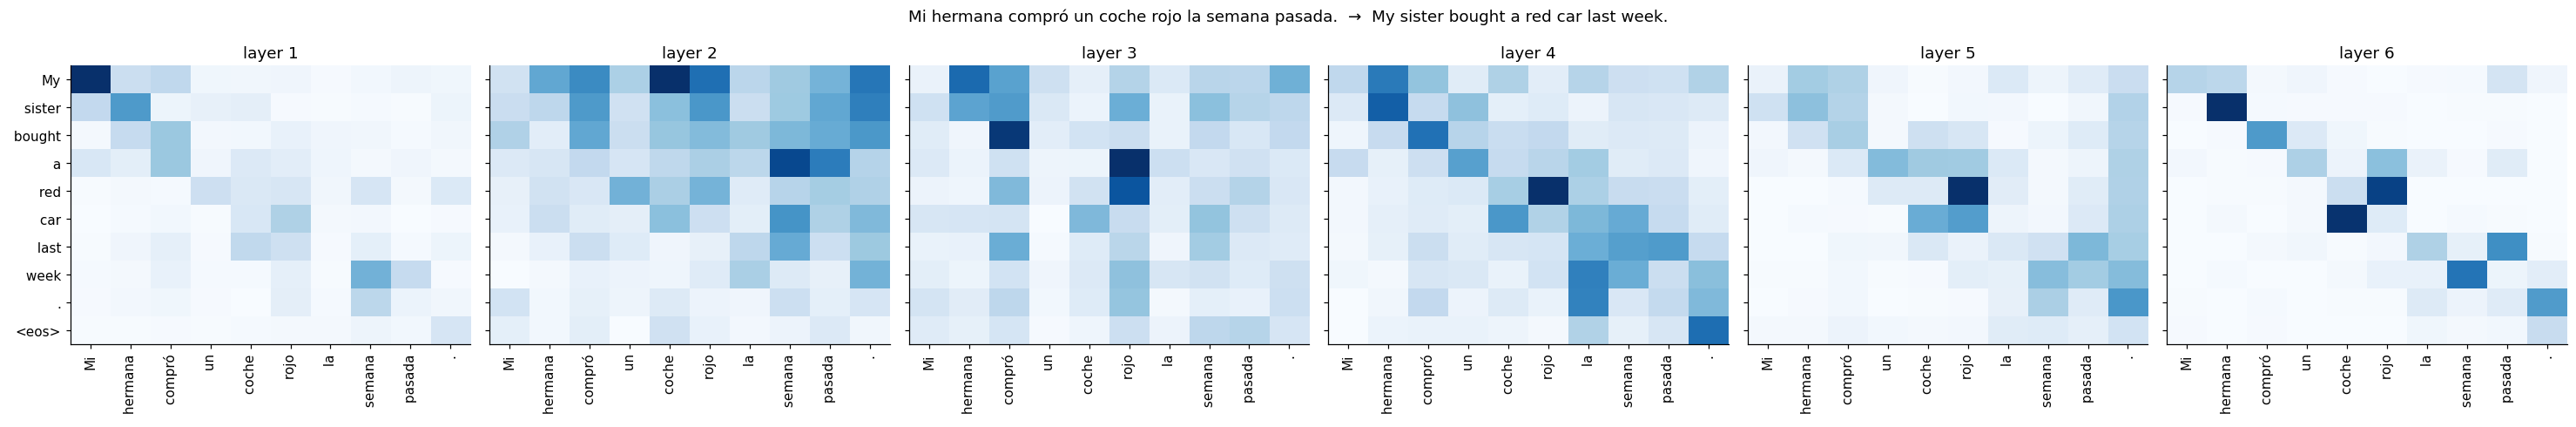

In [30]:
def plot_attention(sentence):
    model.eval()
    prompt = tokenizer.prompt(tokenizer.encode([sentence])[0])
    idx = torch.tensor([prompt], device=DEVICE)
    sequence = model.generate(idx, BLOCK_SIZE - len(prompt), tokenizer.eos_id)[0].tolist()
    attentions = [block.attn for block in model.transformer.h]
    for attn in attentions:
        attn.store_attention = True
    with torch.no_grad():
        model(torch.tensor([sequence[:-1]], device=DEVICE))
    for attn in attentions:
        attn.store_attention = False

    rows = range(len(prompt) - 1, len(sequence) - 1)
    cols = range(1, len(prompt) - 1)
    row_labels = tokenizer.pieces(sequence[len(prompt):])
    col_labels = tokenizer.pieces(sequence[1:len(prompt) - 1])

    fig, axes = plt.subplots(1, len(attentions), figsize=(4.5 * len(attentions), 4.5), squeeze=False)
    for layer, (ax, attn) in enumerate(zip(axes[0], attentions)):
        weights = attn.attention[0].mean(0).float().cpu().numpy()[np.ix_(rows, cols)]
        ax.imshow(weights, cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(col_labels)), col_labels, rotation=90)
        ax.set_yticks(range(len(row_labels)), row_labels if layer == 0 else [])
        ax.set_title(f"layer {layer + 1}")
        ax.grid(False)
    fig.suptitle(f"{sentence}  →  {tokenizer.decode(sequence[len(prompt):])}")
    fig.tight_layout()
    plt.show()


plot_attention("Mi hermana compró un coche rojo la semana pasada.")

### 9.4 Your own sentences

In [31]:
my_sentences = [
    "Mañana voy a entrenar mi propio modelo de lenguaje.",
    "¿Me puedes ayudar a encontrar mis llaves?",
    "El perro de mi vecino ladra toda la noche.",
    "No tengo tiempo para ver películas esta semana.",
    "Ella siempre llega tarde a las reuniones del trabajo.",
    "Si llueve mañana, nos quedaremos en casa.",
    "Te amo Emily Guerrero.",
    "Barcelona es el mejor equipo del mundo.",
    "Tres tristes tigres comen trigo en un trigal.",
    "Las noches son oscuras, pero el dia es claro."
]
pd.DataFrame({"spanish": my_sentences, "model": translator.translate(my_sentences)})

,spanish,model
0,Mañana voy a entrenar mi propio modelo de lenguaje.,I'm going to train my own language model tomorrow.
1,¿Me puedes ayudar a encontrar mis llaves?,Can you help me find my keys?
2,El perro de mi vecino ladra toda la noche.,My neighbor's dog bark all night.
3,No tengo tiempo para ver películas esta semana.,I don't have time to watch movies this week.
4,Ella siempre llega tarde a las reuniones del trabajo.,She is always late for work meetings.
5,"Si llueve mañana, nos quedaremos en casa.","If it rains tomorrow, we'll stay at home."
6,Te amo Emily Guerrero.,"I love you, Emily Warrior."
7,Barcelona es el mejor equipo del mundo.,Barely is the best team in the world.
8,Tres tristes tigres comen trigo en un trigal.,Three sad tigers eat wheat in a trigal.
9,"Las noches son oscuras, pero el dia es claro.","The nights are dark, but the day is clear."


### 9.5 Comparison with the previous run

In [32]:
previous = {
    "parameters (M)": 35.35,
    "epochs trained": 20,
    "best epoch": 15,
    "training time (min)": 133.1,
    "val BLEU": 50.22,
    "val chrF": 65.94,
    "test BLEU": 50.82,
    "test chrF": 66.57,
}
current = {
    "parameters (M)": round(n_params / 1e6, 2),
    "epochs trained": len(epochs),
    "best epoch": int(best["epoch"]),
    "training time (min)": round(train_minutes, 1),
    "val BLEU": round(results.loc["val", "bleu"], 2),
    "val chrF": round(results.loc["val", "chrf"], 2),
    "test BLEU": round(results.loc["test", "bleu"], 2),
    "test chrF": round(results.loc["test", "chrf"], 2),
}
pd.DataFrame({"previous run": previous, "this run": current}, dtype=object)

,previous run,this run
parameters (M),35.35,27.16
epochs trained,20.0,20.0
best epoch,15.0,20.0
training time (min),133.1,51.6
val BLEU,50.22,50.89
val chrF,65.94,66.39
test BLEU,50.82,51.6
test chrF,66.57,66.99
